# Predicting hourly bike rentals in Washington, D.C.
**Group members**

- Rohail Shaikh
- Phaneendra Vanapamula
- Abhilash Reddy Marthala

**MSCS 634 · Residency Day 2 · Regression Modeling and Performance Evaluation**

How much does the distinction between a working-day commute and a day-off afternoon help predict demand? The outcome is the total number of rentals across the system in one recorded hour. The prediction assumes the calendar and that hour’s weather are available. A live forecast would have to supply forecast weather.

## 1. Recover the Day 1 modeling table
The UCI Bike Sharing data cover 2011 and 2012. Day 1 standardized the column names and added a timestamp. We retain genuine peaks and evaluate only recorded hours. Source and attribution appear in the README.

In [1]:
# Locate the dataset relative to the notebook.
from pathlib import Path
# Use NumPy for trigonometry and square roots.
import numpy as np
# Use pandas for hourly records and date-based splits.
import pandas as pd
# Draw the evaluation charts.
import matplotlib.pyplot as plt
# Create independent model instances for each fold.
from sklearn.base import clone
# Apply separate transformations to category and numeric columns.
from sklearn.compose import ColumnTransformer
# Encode categories and standardize numeric inputs.
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Fit preprocessing and regression together within each training split.
from sklearn.pipeline import make_pipeline
# Establish a reference prediction using the training mean.
from sklearn.dummy import DummyRegressor
# Fit linear regression with an L2 penalty.
from sklearn.linear_model import Ridge
# Fit a nonlinear model using successive regression trees.
from sklearn.ensemble import HistGradientBoostingRegressor
# Calculate squared error and explained variation.
from sklearn.metrics import mean_squared_error, r2_score

# Load the Day 1 export and parse timestamps for chronological evaluation.
df = pd.read_csv(Path("bike_sharing_cleaned.csv"), parse_dates=["timestamp"])
# Order recorded hours and use timestamps to select training and validation periods.
df = df.sort_values("timestamp").set_index("timestamp", drop=False)
# Stop if a repeated hour or missing value invalidates the Day 1 assumptions.
assert df.index.is_unique and df.notna().all().all()
# Both component counts are available only after rentals have occurred.
# Check the count identity that makes both component counts unsuitable as predictors.
assert (df.casual_rentals + df.registered_rentals == df.total_rentals).all()
# Report the number of observations and columns loaded.
print(f"{len(df):,} recorded hours, {len(df.columns)} columns")
# Show the first and last hours covered by the dataset.
print(df.index.min(), "through", df.index.max())
# Inspect the target range and quartiles before modeling.
print(df.total_rentals.describe().round(1).to_string())

17,379 recorded hours, 17 columns
2011-01-01 00:00:00 through 2012-12-31 23:00:00
count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0


## 2. Encode calendar structure
Hour 23 and hour 0 are adjacent. Sine and cosine place them next to each other on a daily cycle. A second representation combines the hour with working-day status, allowing each of the 48 combinations to have its own demand level. This can represent narrow commuting peaks that a smooth daily cycle misses. Elapsed days represent gradual growth over the observation period. All three transformations are available before observing rentals.

In [2]:
# Treat calendar codes and weather conditions as categories.
calendar = ["season", "month", "weekday", "working_day", "holiday", "weather"]
# Keep hour and the four normalized weather measurements as numeric predictors.
numeric = ["hour", "temperature_norm", "feels_like_norm", "humidity_norm", "windspeed_norm"]
# Select only the permitted predictors so rental counts cannot leak into training.
X = df[calendar + numeric].copy()
# Predict the total number of bikes rented in each recorded hour.
y = df.total_rentals
# Map each hour to an angle on a 24-hour circle.
angle = 2 * np.pi * X.hour / 24
# Represent the daily cycle with its sine coordinate.
X["hour_sin"] = np.sin(angle)
# Add the cosine coordinate to distinguish hours with the same sine value.
X["hour_cos"] = np.cos(angle)
# Assign separate categories to each hour on working days and days off.
X["hour_by_workday"] = X.hour + 24 * X.working_day
# Measure long-term change in whole days since the dataset began.
X["elapsed_days"] = (df.index.normalize() - pd.Timestamp("2011-01-01")).days
# Inspect sample feature values alongside the hour and day type that produced them.
print(X[["hour", "working_day", "hour_by_workday", "hour_sin", "hour_cos", "elapsed_days"]].head().round(2).to_string())

                     hour  working_day  hour_by_workday  hour_sin  hour_cos  elapsed_days
timestamp                                                                                
2011-01-01 00:00:00     0            0                0      0.00      1.00             0
2011-01-01 01:00:00     1            0                1      0.26      0.97             0
2011-01-01 02:00:00     2            0                2      0.50      0.87             0
2011-01-01 03:00:00     3            0                3      0.71      0.71             0
2011-01-01 04:00:00     4            0                4      0.87      0.50             0


## 3. Define the candidates and evaluation rule
The training mean gives a reference error. The first Ridge model fits an additive regression using raw hour, calendar categories and weather. The second holds the Ridge penalty and original predictors constant and adds the engineered features. Their paired comparison measures the combined feature effect. Ridge shrinks coefficients for overlapping signals such as measured and perceived temperature. Gradient boosting uses the same expanded inputs and fits shallow trees successively to capture nonlinear weather and calendar effects.

Select the model with the lowest mean validation RMSE. Score every candidate on the same four successive calendar quarters, expanding training through the previous quarter each time. The first training window spans nine months. Reserve October–December 2012 for a final check. Fixed settings avoid using the test quarter to tune models.

In [3]:
# Build the preprocessing steps for either the original or expanded inputs.
def preprocessing(expanded):
    # Include the 48 hour-and-day-type categories only for expanded models.
    categories = calendar + (["hour_by_workday"] if expanded else [])
    # Add cyclical time and the growth trend to the expanded numeric inputs.
    numbers = numeric + (["hour_sin", "hour_cos", "elapsed_days"] if expanded else [])
    # Fit category levels and scaling within each training window.
    # Combine the two transformations into one estimator.
    return ColumnTransformer([
        # Encode nominal values without assigning an order and tolerate unseen levels.
        ("calendar", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
        # Learn each numeric column’s center and scale from training hours.
        ("numeric", StandardScaler(), numbers)
    # Return both transformed blocks as one feature matrix.
    ])

# Define the four candidates before inspecting the test period.
models = {
    # Predict the training mean regardless of calendar or weather.
    "Training mean": DummyRegressor(),
    # Fit the original features with a fixed Ridge penalty.
    "Ridge / original": make_pipeline(preprocessing(False), Ridge(alpha=10)),
    # Hold the penalty constant to measure the effect of adding features.
    "Ridge / engineered": make_pipeline(preprocessing(True), Ridge(alpha=10)),
    # Use the expanded features for a model that can learn nonlinear effects.
    "Boosting / engineered": make_pipeline(preprocessing(True), HistGradientBoostingRegressor(
        # Fix the tree size, learning rate, number of boosting rounds and random seed.
        max_iter=180, max_leaf_nodes=31, learning_rate=0.08, early_stopping=False, random_state=42))
# Finish the candidate set used throughout the evaluation.
}
# Reserve the final calendar quarter for testing.
test_start = pd.Timestamp("2012-10-01")
# Choose four successive quarter starts for expanding-window validation.
quarters = pd.date_range("2011-10-01", periods=4, freq="QS")
# Score each set of predictions using the same definitions.
def metrics(actual, predicted):
    # Average the squared differences between predicted and observed counts.
    mse = mean_squared_error(actual, predicted)
    # Return explained variation, squared error and error in rentals per hour.
    return {"R2": r2_score(actual, predicted), "MSE": mse, "RMSE": np.sqrt(mse)}

# Collect one record for each model and validation quarter.
rows = []
# Move the forecast origin forward one quarter at a time.
for start in quarters:
    # Use the next quarter boundary as an exclusive endpoint.
    end = start + pd.DateOffset(months=3)
    # Train only on observations before the validation quarter.
    train = X.index < start
    # Evaluate only recorded hours within this quarter.
    valid = (X.index >= start) & (X.index < end)
    # Check that no fold includes any hour from the final test quarter.
    assert end <= test_start
    # Compare every candidate on the same dates.
    for name, estimator in models.items():
        # Fit a fresh estimator and its preprocessing using earlier hours.
        fitted = clone(estimator).fit(X.loc[train], y.loc[train])
        # Predict rentals for hours the fitted model has never seen.
        pred = fitted.predict(X.loc[valid])
        # Identify the model and quarter for this result.
        rows.append({"Model": name, "Quarter": str(start.to_period("Q")),
                     # Record the sample sizes because the number of recorded hours varies.
                     "Train hours": train.sum(), "Validation hours": valid.sum(),
                     # Store all three validation scores alongside the fold information.
                     **metrics(y.loc[valid], pred)})
# Assemble the fold records into a comparison table.
folds = pd.DataFrame(rows)
# Show individual quarters so seasonal differences remain visible.
print(folds.round(2).to_string(index=False))
# Weight quarters equally and rank candidates by mean validation RMSE.
cv = folds.groupby("Model")[["R2", "MSE", "RMSE"]].mean().sort_values("RMSE")
# Measure how much RMSE varies between the four quarters.
cv["RMSE SD"] = folds.groupby("Model").RMSE.std()
# Select the lowest-error candidate before looking at the test scores.
winner = cv.index[0]
# Identify the table and explain what the dispersion column measures.
print("\nMean across quarters (SD measures variation across quarterly RMSEs)")
# Display the cross-validation summary for every candidate.
print(cv.round(2).to_string())

                Model Quarter  Train hours  Validation hours    R2      MSE   RMSE
        Training mean  2011Q4         6442              2203 -0.00 16310.43 127.71
     Ridge / original  2011Q4         6442              2203  0.32 11122.22 105.46
   Ridge / engineered  2011Q4         6442              2203  0.65  5760.65  75.90
Boosting / engineered  2011Q4         6442              2203  0.79  3480.91  59.00
        Training mean  2012Q1         8645              2176 -0.02 25720.92 160.38
     Ridge / original  2012Q1         8645              2176  0.04 24200.67 155.57
   Ridge / engineered  2012Q1         8645              2176  0.46 13642.73 116.80
Boosting / engineered  2012Q1         8645              2176  0.59 10405.26 102.01
        Training mean  2012Q2        10821              2182 -0.28 59770.97 244.48
     Ridge / original  2012Q2        10821              2182  0.18 38257.91 195.60
   Ridge / engineered  2012Q2        10821              2182  0.74 12250.98 110.68
Boos

## 4. Test the selection on the final quarter
Refit each model on all available earlier hours. RMSE expresses prediction error in rentals per hour and gives extra weight to large misses. MSE is in squared rentals. R² measures improvement over predicting the evaluation period’s mean and can be negative. Keeping the same test rows makes the scores comparable.

In [4]:
# Use every recorded hour before October 2012 for the final fits.
train = X.index < test_start
# Select all remaining recorded hours for held-out evaluation.
test = ~train
# Keep each model’s predictions for scoring and diagnosis.
predictions = {}
# Refit each candidate under identical test conditions.
for name, estimator in models.items():
    # Relearn preprocessing and model parameters from the full training period.
    fitted = clone(estimator).fit(X.loc[train], y.loc[train])
    # Predict rentals for the final quarter and retain the hourly estimates.
    predictions[name] = fitted.predict(X.loc[test])
# Compute the three metrics against the same observed test counts.
scores = pd.DataFrame({name: metrics(y.loc[test], pred)
                       # Arrange the results with one row per model.
                       for name, pred in predictions.items()}).T
# Verify the sizes of the final training and test periods.
print(f"Training hours: {train.sum():,}; test hours: {test.sum():,}")
# Rank the held-out scores by RMSE for comparison.
print(scores.sort_values("RMSE").round(3).to_string())
# Report the model chosen earlier using validation alone.
print("Selected before testing:", winner)

Training hours: 15,211; test hours: 2,168
                          R2        MSE     RMSE
Boosting / engineered  0.780   8950.005   94.604
Ridge / engineered     0.773   9214.861   95.994
Ridge / original       0.197  32638.839  180.662
Training mean         -0.028  41790.948  204.428
Selected before testing: Boosting / engineered


## 5. Compare model errors and diagnose peak demand
The first chart shows the error in each validation quarter. The second compares validation and test errors. The final chart groups held-out hours by observed demand and shows whether the selected model systematically misses busy hours. The dashed diagonal marks exact agreement.

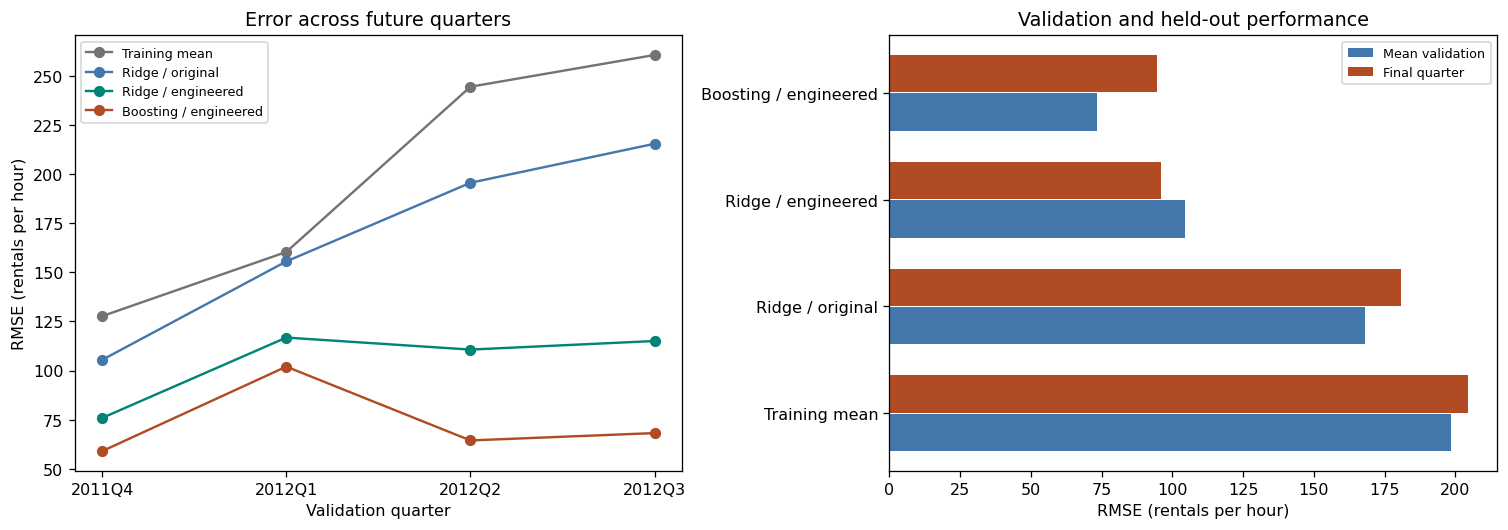

In [5]:
# Assign a distinct line color to each candidate.
colors = ["#737373", "#4477AA", "#008477", "#B04B23"]
# Place quarterly trends and the final comparison side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
# Keep the candidate order consistent with the evaluation table.
for (name, group), color in zip(folds.groupby("Model", sort=False), colors):
    # Mark each quarterly RMSE and connect a model’s scores across time.
    axes[0].plot(group.Quarter, group.RMSE, marker="o", label=name, color=color)
# Label the validation periods and the error units.
axes[0].set(title="Error across future quarters", ylabel="RMSE (rentals per hour)", xlabel="Validation quarter")
# Identify the model represented by each line.
axes[0].legend(fontsize=8)
# Keep the same model order for both sets of bars.
labels = list(models)
# Give each model its own vertical position.
pos = np.arange(len(labels))
# Plot the average validation error for each candidate.
axes[1].barh(pos - 0.18, cv.loc[labels, "RMSE"], height=0.35, color="#4477AA", label="Mean validation")
# Offset the test errors so the two bars can be compared directly.
axes[1].barh(pos + 0.18, scores.loc[labels, "RMSE"], height=0.35, color="#B04B23", label="Final quarter")
# Label model rows and report RMSE in rentals per hour.
axes[1].set(yticks=pos, yticklabels=labels, xlabel="RMSE (rentals per hour)", title="Validation and held-out performance")
# Distinguish the validation and test periods by color.
axes[1].legend(fontsize=8)
# Display the two comparison panels in the notebook.
plt.show()

                observed  predicted
total_rentals                      
(0.999, 10.0]        6.0       16.7
(10.0, 30.0]        18.6       47.0
(30.0, 67.0]        46.0       97.8
(67.0, 122.0]       97.9      171.3
(122.0, 172.0]     147.6      208.7
(172.0, 224.2]     201.0      262.4
(224.2, 287.0]     254.1      303.9
(287.0, 373.0]     328.9      354.7
(373.0, 516.0]     436.9      452.9
(516.0, 963.0]     660.2      648.5


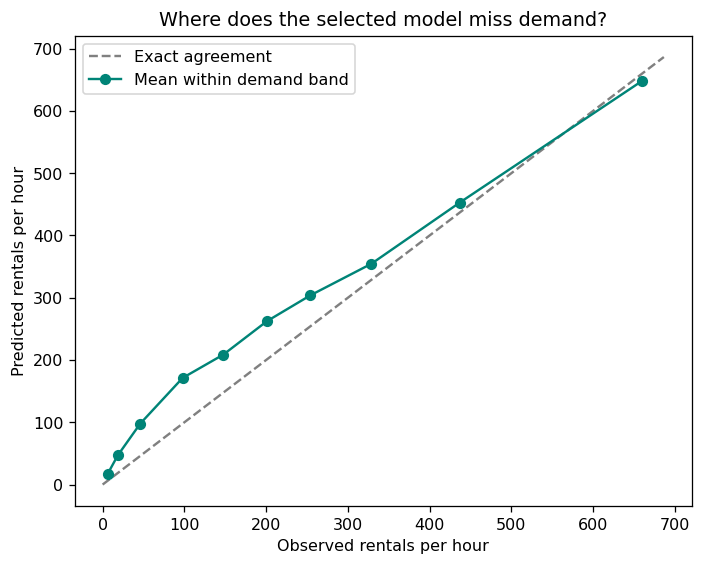

In [6]:
# Retrieve the observed counts for the held-out hours.
actual = y.loc[test]
# Pair observed demand with the selected model’s predictions.
diagnostic = pd.DataFrame({"observed": actual, "predicted": predictions[winner]})
# Sort into roughly equal-sized groups using actual rentals for diagnosis only.
# Average both quantities within groups of similar observed demand.
bands = diagnostic.groupby(pd.qcut(actual, 10, duplicates="drop"), observed=True).mean()
# Create a separate panel for demand-dependent prediction errors.
fig, ax = plt.subplots(figsize=(6, 4.8), layout="constrained")
# Give the agreement line enough range to cover every group mean.
limit = max(bands.max()) * 1.04
# Draw the line where predicted and observed demand match.
ax.plot([0, limit], [0, limit], "--", color="gray", label="Exact agreement")
# Plot each band’s average prediction against its average observed count.
ax.plot(bands.observed, bands.predicted, marker="o", color="#008477", label="Mean within demand band")
# Label both axes in the original rental-count units.
ax.set(xlabel="Observed rentals per hour", ylabel="Predicted rentals per hour",
       # Frame the chart around systematic misses at different demand levels.
       title="Where does the selected model miss demand?")
# Identify the agreement line and the observed group means.
ax.legend()
# Render the diagnostic chart beneath its code.
plt.show()
# Display the exact band averages used to interpret peak-hour errors.
print(bands.round(1).to_string())

## 6. Findings and limitations
**Boosting / engineered** had the lowest mean validation RMSE (73.41 rentals/hour). On the final quarter its RMSE was **94.60**, with R² of **0.780**. The lowest test RMSE belonged to **Boosting / engineered** (94.60).

Adding calendar features reduced mean validation RMSE for Ridge by **63.41 rentals/hour (37.7%)**. Because both Ridge fits used identical folds and penalties, the change measures the combined contribution of the feature set. It does not isolate a single feature.

In the busiest tenth of held-out hours, observed demand averaged **660.2** rentals/hour and predictions averaged **648.5**. A bike allocation plan based solely on that estimate could leave too few bikes available during peaks. These scores describe one city's recorded hours and one final quarter. Future weather forecast errors and changes in ridership could affect performance.